# C. Project Title: Teaching Algerian History using LLMs (Fine-tuning an  LLM + Retrieval-Augmented Generation)

### This notebook provides a comprehensive summary of the code used in our project for the AI generation component (the model). The workflow is organized into three main sections:

#### 1. **Fine-tuning an LLM:** Adapting a large language model to our specific dataset for optimal performance.

#### 2. **Implementing RAG** (Retrieval-Augmented Generation): Leveraging well-organized documents containing the most critical data to enhance the model's output accuracy and relevance.
    
#### 3. **Model Integration:** Combining the fine-tuned LLM with the RAG technique and integrating it into a larger open-source model (hosted) to deliver a user-friendly and high-performance solution.

## All Data can be found in [Drive Folder](https://drive.google.com/drive/folders/1029ESjtsV5Bfu00Ubpy47B3TsjWN-OG5)

#1. Fine-tuning an LLM
In this part many cells of the code are taken from https://github.com/unslothai/unsloth, and all those instructive comments are by them, we prefered to keep them as they are since they are informative

In [ ]:
%%capture
!pip install unsloth
# Also get the latest nightly Unsloth!
!pip uninstall unsloth -y && pip install --upgrade --no-cache-dir "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"

In [ ]:
from unsloth import FastLanguageModel
import torch
max_seq_length = 2048 # Choose any! We auto support RoPE Scaling internally!
dtype = None # None for auto detection. Float16 for Tesla T4, V100, Bfloat16 for Ampere+
load_in_4bit = True # Use 4bit quantization to reduce memory usage. Can be False.

# 4bit pre quantized models we support for 4x faster downloading + no OOMs.
fourbit_models = [
    "unsloth/Meta-Llama-3.1-8B-bnb-4bit",      # Llama-3.1 2x faster
    "unsloth/Meta-Llama-3.1-8B-Instruct-bnb-4bit",
    "unsloth/Meta-Llama-3.1-70B-bnb-4bit",
    "unsloth/Meta-Llama-3.1-405B-bnb-4bit",    # 4bit for 405b!
    "unsloth/Mistral-Small-Instruct-2409",     # Mistral 22b 2x faster!
    "unsloth/mistral-7b-instruct-v0.3-bnb-4bit",
    "unsloth/Phi-3.5-mini-instruct",           # Phi-3.5 2x faster!
    "unsloth/Phi-3-medium-4k-instruct",
    "unsloth/gemma-2-9b-bnb-4bit",
    "unsloth/gemma-2-27b-bnb-4bit",            # Gemma 2x faster!

    "unsloth/Llama-3.2-1B-bnb-4bit",           # NEW! Llama 3.2 models
    "unsloth/Llama-3.2-1B-Instruct-bnb-4bit",
    "unsloth/Llama-3.2-3B-bnb-4bit",
    "unsloth/Llama-3.2-3B-Instruct-bnb-4bit",
] # More models at https://huggingface.co/unsloth

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/Llama-3.2-3B-Instruct-bnb-4bit", # or choose "unsloth/Llama-3.2-1B-Instruct"
    max_seq_length = max_seq_length,
    dtype = dtype,
    load_in_4bit = load_in_4bit,
    # token = "hf_...", # use one if using gated models like meta-llama/Llama-2-7b-hf
)

ImportError: cannot import name 'TensorifyScalarRestartAnalysis' from 'torch._dynamo.exc' (/usr/local/lib/python3.11/dist-packages/torch/_dynamo/exc.py)

We now add LoRA adapters so we only need to update 1 to 10% of all parameters!

In [ ]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 16, # Choose any number > 0 ! Suggested 8, 16, 32, 64, 128
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj",],
    lora_alpha = 16,
    lora_dropout = 0, # Supports any, but = 0 is optimized
    bias = "none",    # Supports any, but = "none" is optimized
    # [NEW] "unsloth" uses 30% less VRAM, fits 2x larger batch sizes!
    use_gradient_checkpointing = "unsloth", # True or "unsloth" for very long context
    random_state = 3407,
    use_rslora = False,  # We support rank stabilized LoRA
    loftq_config = None, # And LoftQ
)

Unsloth 2025.1.5 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


<a name="Data"></a>
### Data Prep
For finetuning, we used a dataset of 9722 rows of questions and answers from different eras and levels.


In [ ]:
alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
Answer the following question in Arabic:

### Input:
{}

### Response:
{}"""

EOS_TOKEN = tokenizer.eos_token # Must add EOS_TOKEN
def formatting_prompts_func(examples):
    inputs = examples["question"]
    outputs = examples["answer"]
    areas = examples["era"]
    levels = examples["level"]
    texts = []

    for input, output, area, level in zip(inputs, outputs, areas, levels):
        # Customize the prompt to include area and level
        text = f"Area: {area}\nLevel: {level}\nQuestion: {input}\nAnswer: {output}\n{EOS_TOKEN}"
        texts.append(text)

    return {"text": texts}


from datasets import load_dataset
# Load the dataset from a local CSV file
dataset = load_dataset("csv", data_files="/kaggle/input/dataset-2/final_qa_merged.csv", split="train")
dataset = dataset.map(formatting_prompts_func, batched = True,)

Generating train split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/9722 [00:00<?, ? examples/s]

In [ ]:
dataset

Dataset({
    features: ['question', 'answer', 'level', 'era', 'text'],
    num_rows: 9722
})

In [ ]:
dataset.shape

(9722, 5)

In [ ]:
print(dataset['text'][10])

Area: الدولة العثمانية
Level: السنة الأولى من التعليم الثانوي
Question: ما هي نتائج الحركات الإصلاحية في الدولة العثمانية؟
Answer: كانت الإصلاحات فاشلة بسبب تأخرها، فقدان السلاطين للخبرة، وإفلاس الخزينة العثمانية.
<|eot_id|>


<a name="Train"></a>
### Train the model
Now let's use Huggingface TRL's `SFTTrainer`! More docs here: [TRL SFT docs](https://huggingface.co/docs/trl/sft_trainer). We 10 epochs which is total of 12000 steps

In [ ]:
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset,
    dataset_text_field = "text",
    max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False, # Can make training 5x faster for short sequences.
    args = TrainingArguments(
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 5,
        num_train_epochs = 10, # Set this for 1 full training run.
        #max_steps = 1,
        learning_rate = 2e-4,
        fp16 = not is_bfloat16_supported(),
        bf16 = is_bfloat16_supported(),
        logging_steps = 1,
        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
    ),
)

Map (num_proc=2):   0%|          | 0/9722 [00:00<?, ? examples/s]

In [ ]:
#@title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = Tesla T4. Max memory = 14.741 GB.
2.205 GB of memory reserved.


In [ ]:
import wandb
wandb.login(key="3bd23f36f0761b7f0cbe365b9c69f5ce1ad3b8bd")


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: yasmina-medjri (yasmina-medjri-ensia). Use `wandb login --relogin` to force relogin
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


True

In [ ]:
trainer_stats = trainer.train() #the output is too long it gives the loss in each step

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs = 1
   \\   /|    Num examples = 9,722 | Num Epochs = 10
O^O/ \_/ \    Batch size per device = 2 | Gradient Accumulation steps = 4
\        /    Total batch size = 8 | Total steps = 12,150
 "-____-"     Number of trainable parameters = 24,313,856
wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.
wandb: Tracking run with wandb version 0.19.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20250112_045701-r29v8zy6
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run outputs
wandb: ⭐️ View project at https://wandb.ai/yasmina-medjri-ensia/huggingface
wandb: 🚀 View run at https://wandb.ai/yasmina-medjri-ensia/huggingface/runs/r29v8zy6


Step,Training Loss
1,3.261100
2,3.369600
3,3.666200
4,3.666100
5,3.324600
6,2.912700
7,2.402900
8,2.569500
9,1.979800
10,2.202100


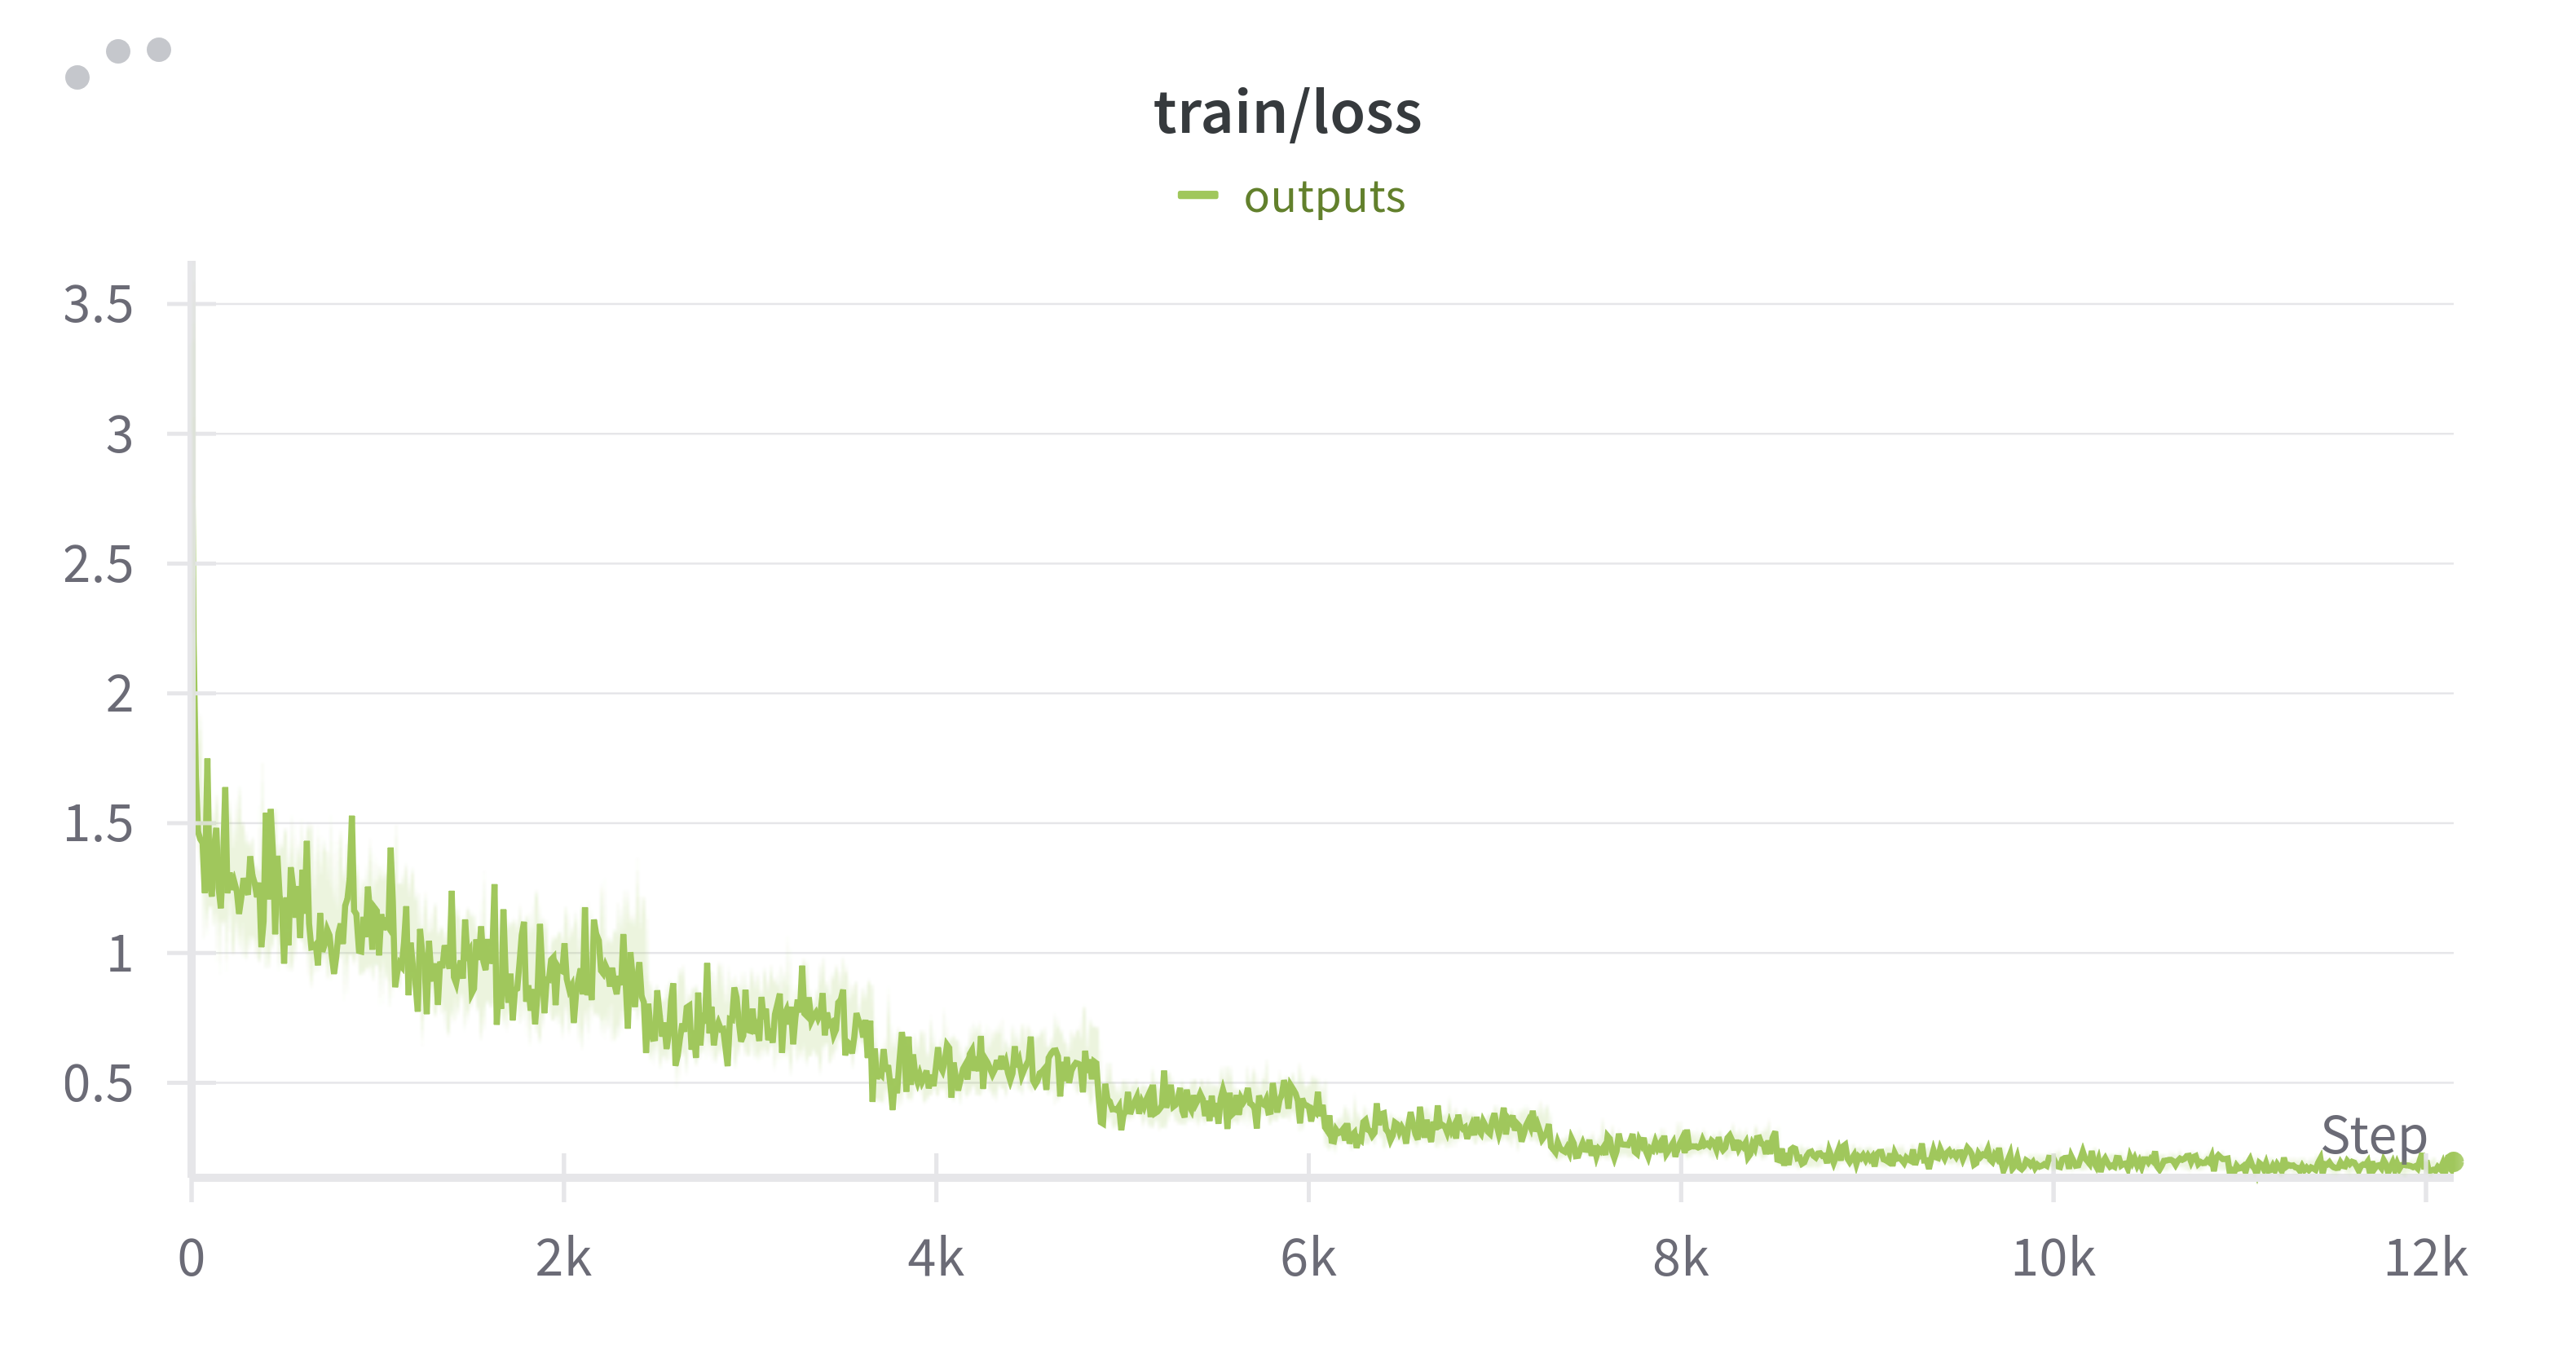

In [ ]:
#@title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory         /max_memory*100, 3)
lora_percentage = round(used_memory_for_lora/max_memory*100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training.")
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

21759.4363 seconds used for training.
362.66 minutes used for training.
Peak reserved memory = 2.744 GB.
Peak reserved memory for training = 0.539 GB.
Peak reserved memory % of max memory = 18.615 %.
Peak reserved memory for training % of max memory = 3.656 %.


<a name="Save"></a>
### Saving, loading finetuned models
To save the final model as LoRA adapters, we use Huggingface's `push_to_hub` for an online save .

**[NOTE]** The saved models are public and can be viewed on https://huggingface.co/yasmina3

and last model used is the following  https://huggingface.co/yasmina3/History-final-Llama-3.2-3B-Instruct-bnb-4bit

In [ ]:
from google.colab import userdata
import os
HF_token = "put-token-here" # Replace with your actual token
os.environ["HF_token"] = HF_token

In [ ]:
#model.save_pretrained("lora_model") # Local saving
#tokenizer.save_pretrained("lora_model")
model.push_to_hub("yasmina3/History-final-Llama-3.2-3B-Instruct-bnb-4bit", token = HF_token) # Online saving
tokenizer.push_to_hub("yasmina3/History-final-Llama-3.2-3B-Instruct-bnb-4bit", token = HF_token) # Online saving

README.md:   0%|          | 0.00/597 [00:00<?, ?B/s]

  0%|          | 0/1 [00:00<?, ?it/s]

adapter_model.safetensors:   0%|          | 0.00/97.3M [00:00<?, ?B/s]

Saved model to https://huggingface.co/yasmina3/History-final-Llama-3.2-3B-Instruct-bnb-4bit


  0%|          | 0/1 [00:00<?, ?it/s]

tokenizer.json:   0%|          | 0.00/17.2M [00:00<?, ?B/s]

In [ ]:
from unsloth import FastLanguageModel
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/Llama-3.2-3B-Instruct-bnb-4bit", # MODEL USED FOR TRAINING BEFORE FINE TUNE
    max_seq_length = 2048,
    dtype = None,
    load_in_4bit = True,
)
FastLanguageModel.for_inference(model) # Enable native 2x faster inference

alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
Answer the following question in Arabic:

### Input:
{}

### Response:
{}"""

inputs = tokenizer(
[
    alpaca_prompt.format(
        "كيف ساهمت الجزائر في الحفاظ على سيادتها البحرية", # input
        "", # output - leave this blank for generation!
    )
], return_tensors = "pt").to("cuda")

from transformers import TextStreamer
text_streamer = TextStreamer(tokenizer)
_ = model.generate(**inputs, streamer = text_streamer, max_new_tokens = 128)

==((====))==  Unsloth 2025.1.5: Fast Llama patching. Transformers: 4.48.0.
   \\   /|    GPU: Tesla T4. Max memory: 14.741 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.5.1+cu124. CUDA: 7.5. CUDA Toolkit: 12.4. Triton: 3.1.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.29.post1. FA2 = False]
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
<|begin_of_text|>Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
Answer the following question in Arabic:

### Input:
كيف ساهمت الجزائر في الحفاظ على سيادتها البحرية

### Response:
الجزائر كانت تعمل على الحفاظ على سيادتها البحرية من خلال إنشاء جيش بحرية قوي، والتعاون مع الدول الأخرى في المنطقة لمنع أي محاولات إقناع أو إزعاجها. كما كانت الجزائر تعمل على تعزيز قوتها البحرية من خلال التطوير وتحديث أساطيلها وتطوير القو

Now if you want to load the LoRA adapters we just saved for inference, set `False` to `True`:

In [ ]:
from unsloth import FastLanguageModel
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "yasmina3/History-final-Llama-3.2-3B-Instruct-bnb-4bit", # FINETUNED MODEL
    max_seq_length = 2048,
    dtype = None,
    load_in_4bit = True,
)
FastLanguageModel.for_inference(model) # Enable native 2x faster inference

alpaca_prompt = """you are an AI history teacher, you only answer based on historical data, and you talk strictly in arabic

### Instruction:
Answer the following question in Arabic:

### Input:
{}

### Response:
{}"""

inputs = tokenizer(
[
    alpaca_prompt.format(
       "اشرح مفهوم 'العلاقات الداخلية'", # input
        "", # output - leave this blank for generation!
    )
], return_tensors = "pt").to("cuda")

from transformers import TextStreamer
text_streamer = TextStreamer(tokenizer)
_ = model.generate(**inputs, streamer = text_streamer, max_new_tokens = 128)


print("\n--- Generating Response ---\n")
generated_output = model.generate(
    **inputs,
    streamer=text_streamer,
    max_new_tokens=128
)

# Optional: Format and display the response cleanly
# Decode and print the generated response
decoded_output = tokenizer.decode(generated_output[0], skip_special_tokens=True)
formatted_output = decoded_output.replace("### Response:", "\n### Response:\n").strip()

print("\n--- Final Output ---")
print(formatted_output)

==((====))==  Unsloth 2025.1.5: Fast Llama patching. Transformers: 4.48.0.
   \\   /|    GPU: Tesla T4. Max memory: 14.741 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.5.1+cu124. CUDA: 7.5. CUDA Toolkit: 12.4. Triton: 3.1.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.29.post1. FA2 = False]
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


adapter_model.safetensors:   0%|          | 0.00/97.3M [00:00<?, ?B/s]

<|begin_of_text|>you are an AI history teacher, you only answer based on historical data, and you talk strictly in arabic

### Instruction:
Answer the following question in Arabic:

### Input:
اشرح مفهوم 'العلاقات الداخلية'

### Response:
الرؤية الداخلية هي مبدأ اعتمد عليه الكفاح التحرري، وهو رفض التبعية لمن أخر سياسي أو قومي.

<|eot_id|>

--- Generating Response ---

<|begin_of_text|>you are an AI history teacher, you only answer based on historical data, and you talk strictly in arabic

### Instruction:
Answer the following question in Arabic:

### Input:
اشرح مفهوم 'العلاقات الداخلية'

### Response:
الرأي: العلاقات الداخلية هي العلاقة بين الحاكم والرعية ويشمل التعاون والتعاون بين القبائل العربية
الشريعة: العلاقات الداخلية تميزت بأهمية قصبة الجفاف وبناء المدن وتنظيم الجيش
الوضع التاريخي: في العهد النبي وعدة أشهر من خلافة عمر بن الخطاب
الاستعمار الأجنبي: كان للعلاقات الداخلية دور كبير في مقاومة الاحتلال الأجنبي خاصة الأجنبي الألماني
<|eot_id|>

--- Final Output ---
you are an AI histo

### GGUF / llama.cpp Conversion
To save to `GGUF` / `llama.cpp`, we support it natively now! We clone `llama.cpp` and we default save it to `q8_0`. We allow all methods like `q4_k_m`. Use `save_pretrained_gguf` for local saving and `push_to_hub_gguf` for uploading to HF.

Some supported quant methods (full list on our [Wiki page](https://github.com/unslothai/unsloth/wiki#gguf-quantization-options)):
* `q8_0` - Fast conversion. High resource use, but generally acceptable.
* `q4_k_m` - Recommended. Uses Q6_K for half of the attention.wv and feed_forward.w2 tensors, else Q4_K.
* `q5_k_m` - Recommended. Uses Q6_K for half of the attention.wv and feed_forward.w2 tensors, else Q5_K.

[**NEW**] To finetune and auto export to Ollama, try our [Ollama notebook](https://colab.research.google.com/drive/1WZDi7APtQ9VsvOrQSSC5DDtxq159j8iZ?usp=sharing)

In [ ]:
#model.save_pretrained_gguf("Arabic-Law-Meta-Llama-3.2-3B-GGUF", tokenizer, quantization_method = "q4_k_m")
#model.push_to_hub_gguf("AhmedBou/Arabic-Law-Meta-Llama-3.2-3B-GGUF", tokenizer, quantization_method = "q4_k_m", token = HF_token)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pinecone-io/examples/blob/master/integrations/groq/groq-llama-3-rag.ipynb) [![Open nbviewer](https://raw.githubusercontent.com/pinecone-io/examples/master/assets/nbviewer-shield.svg)](https://nbviewer.org/github/pinecone-io/examples/blob/master/integrations/groq/groq-llama-3-rag.ipynb)

#2.  Implementing RETREIVAL AUGMENTED GENERATION

To begin, we setup our prerequisite libraries.

In [ ]:
!pip install -qU \
    datasets==2.14.5 \
    groq==0.8.0 \
    "semantic-router[local]==0.0.45" \
    pinecone-client==4.1.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 4.7 MB/s eta 0:00:00


In [ ]:
pip install --upgrade groq

  Using cached groq-0.18.0-py3-none-any.whl.metadata (14 kB)
Using cached groq-0.18.0-py3-none-any.whl (121 kB)
  Attempting uninstall: groq
    Found existing installation: groq 0.8.0
    Uninstalling groq-0.8.0:
      Successfully uninstalled groq-0.8.0


In [ ]:
from groq import Groq
import os
import getpass

api_key1="-" #this is my personal api key but it is left here for ease f testing for the teacher
groq_client = Groq(api_key=api_key1)

## Data Preparation

This part or the code is in fact repeated many times, since a different dataset and index is created for each level

- Datasets can be viewed on : https://huggingface.co/yasmina3

In [ ]:
from huggingface_hub import login

# You will be prompted to enter your Hugging Face token (
login()
# Save your dataset to a dataset repository



In [ ]:

import pandas as pd
from datasets import Dataset

# Step 1: Load your CSV file
csv_file_path = '1HS.csv'
df = pd.read_csv(csv_file_path)

# Ensure the CSV has the expected columns
# Assuming the columns are 'title', 'domain', and 'paragraph'
assert 'الوحدة' in df.columns
assert 'الوضعية' in df.columns
assert 'النص' in df.columns

# Step 2: Define the minimum word count threshold for a paragraph
MIN_WORDS = 30

# Step 3: Combine short paragraphs with the next one
filtered_paragraphs = []
titles = []
domains = []
temp_paragraph = ""
temp_title = ""
temp_domain = ""

for index, row in df.iterrows():
    paragraph = row['النص'].strip()
    title = row['الوحدة'].strip()
    domain = row['الوضعية'].strip()

    if len(paragraph.split()) < MIN_WORDS:  # Check if the paragraph is short
        temp_paragraph += " " + paragraph  # Append short paragraph to the temp
        temp_title = title  # Retain the title for the combined paragraph
        temp_domain = domain  # Retain the domain for the combined paragraph
    else:
        if temp_paragraph:  # Append temp paragraph if exists
            filtered_paragraphs.append(temp_paragraph + " " + paragraph)
            titles.append(temp_title)
            domains.append(temp_domain)
            temp_paragraph = ""  # Reset the temp paragraph
        else:
            filtered_paragraphs.append(paragraph)
            titles.append(title)
            domains.append(domain)

# Add any remaining content in temp_paragraph
if temp_paragraph:
    filtered_paragraphs.append(temp_paragraph.strip())
    titles.append(temp_title)
    domains.append(temp_domain)

# Step 4: Prepare the data as a dictionary for Hugging Face Dataset
data_dict = {
    "id": list(range(len(filtered_paragraphs))),
    "content": filtered_paragraphs,
    "title": titles,
    "era": domains  #lwad3iya
}

# Step 5: Create a Hugging Face dataset
text_data = Dataset.from_dict(data_dict)

# Step 6: Inspect the dataset
print(f"Total paragraphs: {len(text_data)}")
print(text_data[:5])  # Inspect the first 5 records

# Step 7: Save the processed dataset (optional)
text_data.save_to_disk("processed_csv_dataset")


FileNotFoundError: [Errno 2] No such file or directory: '1HS.csv'

In [ ]:
from datasets import Dataset

# Save the dataset to Hugging Face's dataset hub
dataset_name = "1HS_alg_history"

text_data.push_to_hub(dataset_name)


Pushing dataset shards to the dataset hub:   0%|          | 0/1 [00:00<?, ?it/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

We have 200K chunks, where each chunk is roughly the length of 1-2 paragraphs in length. Here is an example of a single record:

In [ ]:
from datasets import load_dataset

data = load_dataset(
    "yasmina3/1HS_alg_history",
    split="train[:152]"
)
data

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Extracting data files:   0%|          | 0/1 [00:00<?, ?it/s]

Generating train split:   0%|          | 0/152 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'content', 'title', 'era'],
    num_rows: 152
})

Format the data into the format we need, this will contain `id`, `title`, `era`, `content` (which we will embed), and `metadata`.

In [ ]:
data = data.map(lambda x: {
    "id": x["id"],
    "metadata": {
        "title": x["title"], #represents الوحدة
        "era": x["era"], #represents الوضعية
        "content": f"{x['title']} : {x['era']} : {x['content']}" #represents the content
    }
})
# drop uneeded columns
data = data.remove_columns([
    "title", "content", "era"
])
data

NameError: name 'data' is not defined

In [ ]:
data[0]

{'id': 0,
 'metadata': {'content': 'الوحدة 1: العالم الاسلامي وضعه الداخلي و علاقاته الخارجية : الوضعية 1: أوضاع العالم الاسلامي : يكتسي حوض البحر المتوسط أهمية قصوى باعتباره منطقة حضارية، نشأت على ضفافه حضارات راقية من أمازيغية وفرعونية وفينيقية ويونانية ورومانية وعربية إسلامية، ومن كونه ممرًا عالميًا للعبور والتجارة. وفي مطلع العصر الحديث، برزت على ضفافه عدة قوى سياسية، أبرزها تلك التي تمركزت في جنوب غرب القارة الأوروبية وشرق البحر المتوسط وشمال غرب إفريقيا. أوضاع العالم الإسلامي'}}

We need to define an embedding model to create our embedding vectors for retrieval, for that we will be using a variation of the `e5-base` model with a longer context length of `4k` tokens. Ideally we should be running this on GPU for optimal runtimes.

In [ ]:
!pip install semantic-router --upgrade

from semantic_router.encoders import HuggingFaceEncoder

encoder = HuggingFaceEncoder(name="dwzhu/e5-base-4k")

  Using cached semantic_router-0.0.72-py3-none-any.whl.metadata (10 kB)
Using cached semantic_router-0.0.72-py3-none-any.whl (85 kB)
  Attempting uninstall: semantic-router
    Found existing installation: semantic-router 0.0.45
    Uninstalling semantic-router-0.0.45:
      Successfully uninstalled semantic-router-0.0.45


tokenizer_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/228 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/691 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/225M [00:00<?, ?B/s]

We can check whether our `encoder` will use `cpu` or a `cuda` GPU (where available).

In [ ]:
encoder.device

'cuda'

We can create embeddings now like so:

In [ ]:
embeds = encoder(["this is a test"])

We can view the dimensionality of our returned embeddings, which we'll need soon when initializing our vector index:

In [ ]:
dims = len(embeds[0])
dims

768

Now we create our vector DB to store our vectors. For this we need to get a [free Pinecone API key](https://app.pinecone.io) — the API key can be found in the "API Keys" button found in the left navbar of the Pinecone dashboard.

In [ ]:
import os
import getpass
from pinecone import Pinecone

# initialize connection to pinecone (get API key at app.pinecone.io)
api_key = os.getenv("PINECONE_API_KEY") or getpass.getpass("Enter your Pinecone API key: ")

# configure client
print("If you are trying this, there is no need indexes are created and stored and can be used directly")
pc = Pinecone(api_key=api_key)

Enter your Pinecone API key: ··········


If you are trying this, there is no need indexes are created and stored and can be used directly

Now we setup our index specification, this allows us to define the cloud provider and region where we want to deploy our index. You can find a list of all [available providers and regions here](https://docs.pinecone.io/docs/projects).

In [ ]:
from pinecone import ServerlessSpec

spec = ServerlessSpec(
   cloud="aws", region="us-east-1"
)

Creating an index, we set `dimension` equal to the dimensionality of our encoder (`768`), and use a `metric` also compatible with the model (this can be `cosine`). We also pass our `spec` to index initialization.

In [ ]:
import time

index_name = "3hs-history"
existing_indexes = [
    index_info["name"] for index_info in pc.list_indexes()
]

# check if index already exists (it shouldn't if this is first time)
if index_name not in existing_indexes:
    # if does not exist, create index
    pc.create_index(
        index_name,
        dimension=dims,
        metric='cosine',
        spec=spec
    )
    # wait for index to be initialized
    while not pc.describe_index(index_name).status['ready']:
        time.sleep(1)

# connect to index
index = pc.Index(index_name)
time.sleep(1)
# view index stats
index.describe_index_stats()

{'dimension': 768,
 'index_fullness': 0.0,
 'namespaces': {'': {'vector_count': 649}},
 'total_vector_count': 649}

We can see the index is currently empty with a `total_vector_count` of `0`. We can begin populating it with our embeddings.

In [ ]:
from tqdm.auto import tqdm

batch_size = 128  # how many embeddings we create and insert at once

for i in tqdm(range(0, len(data), batch_size)):
    # find end of batch
    i_end = min(len(data), i+batch_size)
    # create batch
    batch = data[i:i_end]
    # chunks = [f'{x["title"]} : {x["era"]} : {x["content"]}' for x in batch["metadata"]]
    chunks = [f' {x["content"]}' for x in batch["metadata"]]
    embeds = encoder(chunks)
    assert len(embeds) == (i_end-i)
    # Convert id to string
    to_upsert = [(str(x[0]), x[1], x[2]) for x in zip(batch["id"], embeds, batch["metadata"])]
    # upsert to Pinecone
    index.upsert(vectors=to_upsert)


NameError: name 'data' is not defined

In [ ]:
batch["metadata"]

[{'content': 'الوحدة 3: الجزائر في العصر الحديث : الوضعية 2: الدولة الجزائرية في ظل الحكم العثماني : إن الأملاك الموقوفة أو المحبسة، باختلاف أنواعها وتعدد أصنافها، تطلبت تنظيم مؤسسات خيرية للإشراف عليها وضمانها طبقًا لحكام الوقف الشرعية التي تبعده عن إجراءات البيع والشراء والوراثة. وكان الوقف في حد ذاته موجهًا لخدمة الجماعة عملاً بالسنة النبوية. وقد أخذ شكل مؤسسات خيرية تطورت في البيئات الإسلامية عبر الفترات التاريخية المختلفة، مما أكسبه إطارًا تشريعيًا وجعله واحدًا من العوامل المهمة في الحياة الاجتماعية والعمرانية للمجتمعات الإسلامية. إبراهيم بن يوسف، "مجلة دراسات إنسانية" (عدد خاص) المراكز الثقافية في العصر العثماني'},
 {'content': 'الوحدة 3: الجزائر في العصر الحديث : الوضعية 2: الدولة الجزائرية في ظل الحكم العثماني : امتاز العصر العثماني في الجزائر بانتقال المراكز الثقافية من المدن إلى الجبال والقرى. واشتهرت عدة معاهد في كامل القطر الجزائري، مثل معاهد يعلى العجيسي، عبد الرحمان يلولي، الإدريسي، قرومة، ببي خليل، وغيرها. كما تم تأسيس معاهد جديدة مثل معهد الراشدية، مازونة، والونشريس، وا

Now let's test retrieval!

In [ ]:
def get_docs(query: str, top_k: int) -> list[str]:
    # encode query
    xq = encoder([query])
    # search pinecone index
    res = index.query(vector=xq, top_k=top_k, include_metadata=True)
    # get doc text
    docs = [x["metadata"]['content'] for x in res["matches"]]
    return docs

We prefer to remove stop words and frequent words from the query so that the similarity is only based on important words

In [ ]:
import nltk
from nltk.corpus import stopwords
from collections import Counter
import re

# Download the stopwords list for Arabic
nltk.download('stopwords')

def remove_stop_words_and_frequent_words(text, frequent_words_threshold=5):
    # Step 1: Tokenize the sentence (split into words)
    words = re.findall(r'\b\w+\b', text.lower())  # Use regex to handle Arabic words

    # Step 2: Load Arabic stop words from NLTK
    stop_words = set(stopwords.words('arabic'))

    # Step 3: Remove stop words from the text
    filtered_words = [word for word in words if word not in stop_words]

    # Step 4: Calculate word frequencies in the filtered text
    word_freq = Counter(filtered_words)

    # Step 5: Filter out frequent words based on a threshold
    filtered_words = [word for word in filtered_words if word_freq[word] <= frequent_words_threshold]

    # Step 6: Join the remaining words back into a sentence
    cleaned_text = ' '.join(filtered_words)

    return cleaned_text

# Example usage:
text = "اللغة العربية جميلة، لكنها تحتوي على الكثير من الكلمات الشائعة التي يمكن تجاهلها"
cleaned_text = remove_stop_words_and_frequent_words(text)
print(cleaned_text)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


اللغة العربية جميلة لكنها تحتوي الكثير الكلمات الشائعة يمكن تجاهلها

In [ ]:
query = "ما هو التزام الجزائر تجاه القضية الفلسطينية؟"
#query = "ما هي النتائج السياسية لانتصارات الاتحاد السوفييتي في الحرب؟"
#query = "ما هي أهداف مؤتمر التعاون الاقتصادي الدولي في باريس 1975؟"
#query = "ما القرار الذي اتخذه الرئيس كينيدي عام 1961؟"
#query = "ماذا نصت المادة 6 من دستور 1976؟"
cleaned_query = remove_stop_words_and_frequent_words(query)
print(cleaned_query)
docs = get_docs(cleaned_query, top_k=1)
print("\n---\n".join(docs))

التزام الجزائر القضية الفلسطينية

الوحدة الثانية: تطور العالم الثالث ما بين 1945 - 1989 : الوضعية الثالثة: انعكاسات علاقات الثنائية القطبية على 
العالم. : فلسطين تمثل الظلم التاريخي والإنساني في أجلى صوره، إنها أكبر عملية سطو في التاريخ، ذلك أن الاحتلال 
الاستيطاني الصهيوني يدعي حقا تاريخيا في الأرض المحتلة، فاضطهد أهلها وشردهم ودمر منازلهم ونكل بأبنائهم زاجا بهم في 
السجون ومراكز الاعتقال، حدث ولا يزال يحدث ذلك تحت غطاء ومساندة من قبل الدول الغربية، التي تنقل لشعوبها إعلاميا صورة
مشوهة للنزاع الفلسطيني الصهيوني، ما شجع إسرائيل على تعنتها وضربها عرض الحائط كل القوانين والقرارات الأممية بشأن 
تسوية القضية الفلسطينية.

Our retrieval component works, now let's try feeding this into a Llama 3 70B model hosted by Groq to produce an answer.

In [ ]:
from groq import Groq

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY") or getpass.getpass("Enter your Groq API key: ")

groq_client = Groq(api_key=os.environ["GROQ_API_KEY"])

Enter your Groq API key: ··········


Now we can generate responses using Llama 3, we'll wrap this logic into a help function called `generate`: (this is only to test the RAG with open source hosted model)

In [ ]:
def generate(query: str, docs: list[str]):
    system_message = (
        "You are a helpful assistant that answers questions about history you answer only in arabic"
        "The following context might be relevant and useful for the answer, if not answer by yourself.\n\n"
        "CONTEXT:\n"
        "\n---\n".join(docs)
    )
    messages = [
        {"role": "system", "content": system_message},
        {"role": "user", "content": query}
    ]
    # generate response
    chat_response = groq_client.chat.completions.create(
        model="llama-3.2-90b-vision-preview",
        messages=messages
    )
    return chat_response.choices[0].message.content

In [ ]:
out = generate(query=query, docs=docs)
print(out)

تولدت فكرة الجمهورية في إنجلترا خلال القرن السابع عشر، حيث لم تكن مسألة الملكية مطلبًا ضروريًا للاستقرار السياسي في ذلك الوقت.然而، أدت أسباب متعددة إلى تحول إنجلترا من ملكية إلى جمهورية خلال فترة حكم أوليفر كرومويل:

أولًا: هيمنة البرلمان على الحكومة:
 حصلت حرب أهلية في إنجلترا بين 1642 و1651، حيث كان من أحد أطرافها الملك تشارلز الأول، ومن الطرف الآخر البرلمان. فاز البرلمان بقيادة أوليفر كرومويل، وألغى هذا الأخير النظام الملكي في 1649م، حيث أصبح كرومويل القائد العام للقوات البرلمانية.

ثانيًا: تأسيس الكومنولث الإنجليزي:
في 1649، تم إلغاء الملكية وأعلن تأسيس الكومنولث الإنجليزي. ترأس أوليفر كرومويل الحكومة وتم تعيينه على رأس كميسيون الكومنولث مع nhóm كبير من أعضاء البرلمان.

ثالثًا: هيمنة كرومويل:
خلال فترة رئاسته، قام كرومويل بقضايا داخلية عميقة، كإصلاح النظام القضائي بين دیگر النظم. ومع ذلك، تدهورت علاقته مع البرلمان، وساهم كرومويل في منعه، وأصبح كرومويل الديكتاتور الفعلي غير الشكلي لإنجلترا.

نظرية الجمهورية:
بقي كرومويل في المنصب حتى وفاته سنة 1658م. بعد ذلك، عانت إنجلترا من عدم الاس

THIS CELL DELETES THE INDEX!



In [ ]:
# index_name = "..."
# pc.delete_index(index_name)

---

#3. Model Integration



1.   Import models
2.   Prepare the tools list
3.   Create a basic conversationnal Chatbot
3.   Initialize the rag indexes
4.   Integrate the tools and indexes




## 1.Import Models

In [ ]:
%%capture
!pip install unsloth
# Also get the latest nightly Unsloth!
!pip uninstall unsloth -y && pip install --upgrade --no-cache-dir "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"

In [ ]:
from unsloth import FastLanguageModel
from transformers import TextStreamer

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [ ]:
History_Meta_Llama_LoRA = "yasmina3/History-final-Llama-3.2-3B-Instruct-bnb-4bit"

In [ ]:
# Load the model and tokenizer: Medicine_Meta_Llama_LoRA
history_model, history_tokenizer = FastLanguageModel.from_pretrained(
    model_name= History_Meta_Llama_LoRA,
    max_seq_length=2048,
    dtype=None,
    load_in_4bit=True,
)

# Enable faster inference
FastLanguageModel.for_inference(history_model)

==((====))==  Unsloth 2025.2.4: Fast Llama patching. Transformers: 4.48.2.
   \\   /|    GPU: Tesla T4. Max memory: 14.741 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.6.0+cu124. CUDA: 7.5. CUDA Toolkit: 12.4. Triton: 3.2.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.29.post2. FA2 = False]
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/2.35G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/234 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.7k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.2M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

adapter_model.safetensors:   0%|          | 0.00/97.3M [00:00<?, ?B/s]

Unsloth 2025.2.4 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): LlamaForCausalLM(
      (model): LlamaModel(
        (embed_tokens): Embedding(128256, 3072, padding_idx=128004)
        (layers): ModuleList(
          (0): LlamaDecoderLayer(
            (self_attn): LlamaAttention(
              (q_proj): lora.Linear4bit(
                (base_layer): Linear4bit(in_features=3072, out_features=3072, bias=False)
                (lora_dropout): ModuleDict(
                  (default): Identity()
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=3072, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=3072, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
              (k_proj): lora.Linear

## 2.Prepare the tools list

### **We choose to use our fine tuned llm as a tool or a function for a biger llm to make more organized and user freindly answers, merging between the power of the big model (70b params) and the domain specific knowledge of our small finetuned model**

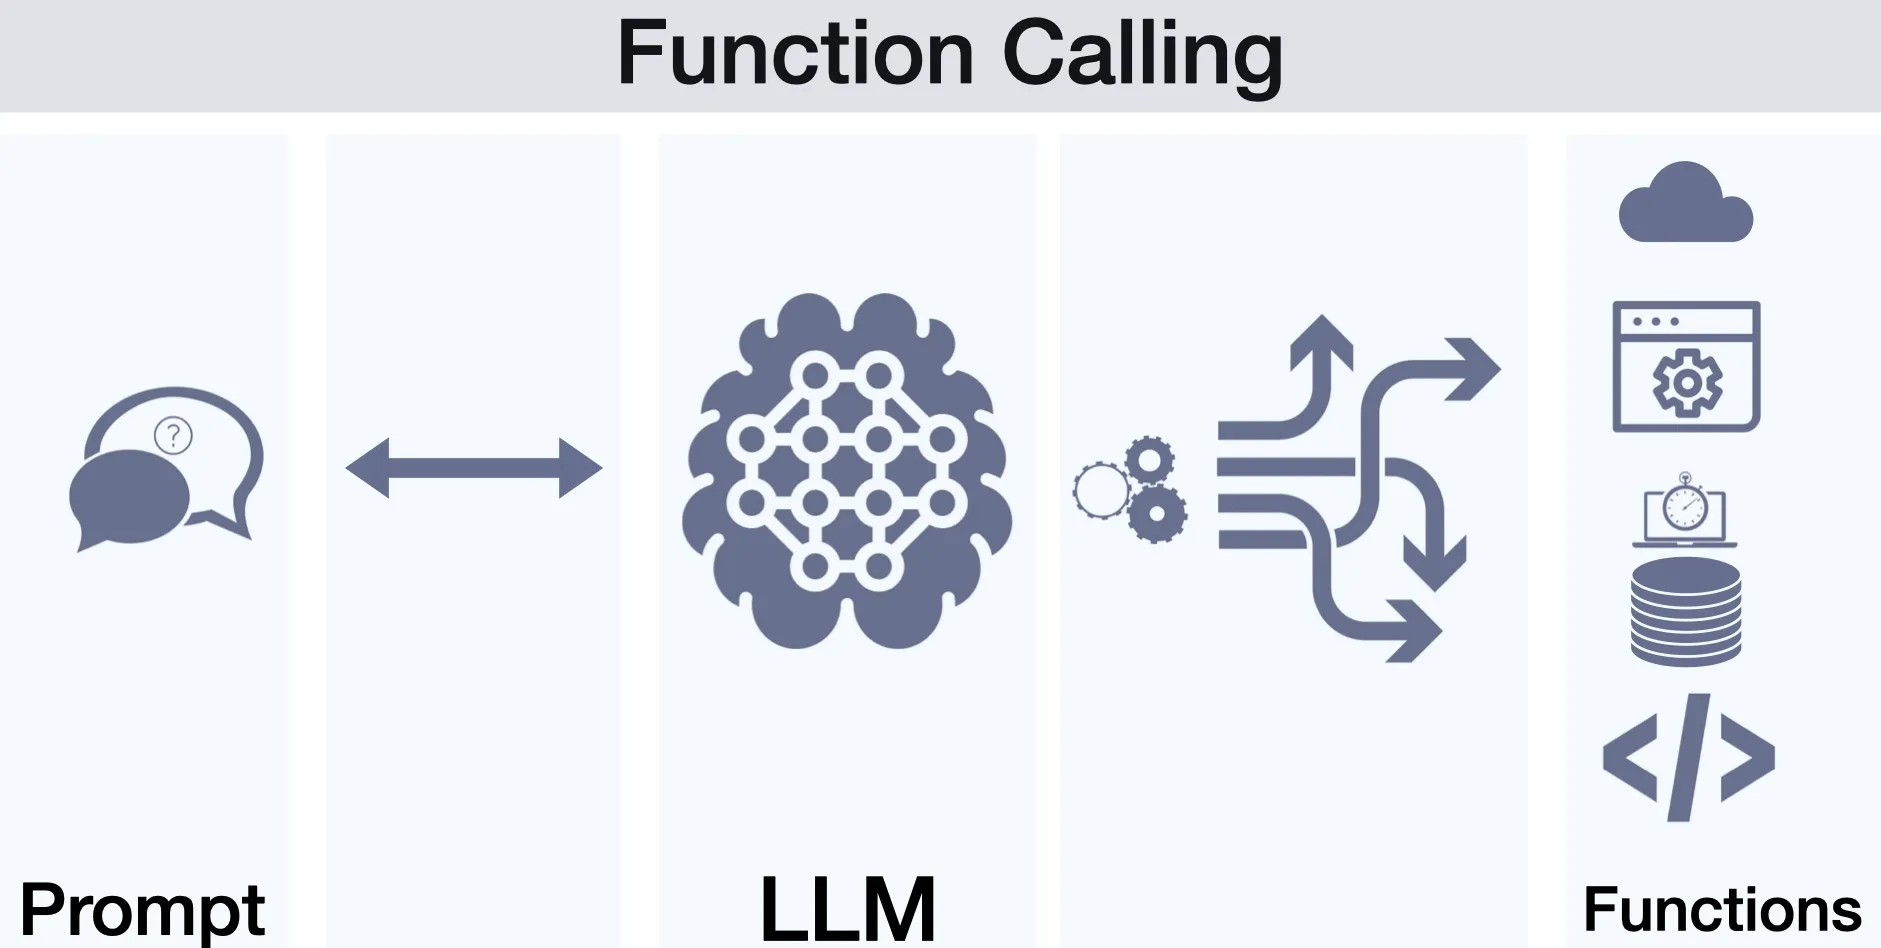

In [ ]:
  # Alpaca-style prompt template
alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a detailed response.

### Instruction:
Answer the following question in Arabic about History, use only arabic and be precise:

### Input:
{}

### Response:
{}"""

In [ ]:
def parse_response(output):
    # Ensure the output is a string
    if isinstance(output, list):
        output = output[0]

    # Define the start and end markers
    start_marker = "### Response:\n"
    end_marker = "<|eot_id|>"

    # Extract the response between the markers
    if start_marker in output and end_marker in output:
        start_index = output.index(start_marker) + len(start_marker)
        end_index = output.index(end_marker)
        response = output[start_index:end_index].strip()
        return response
    return None

In [ ]:
def get_history_answers(question, alpaca_prompt=alpaca_prompt, model=history_model, tokenizer=history_tokenizer):

    # Prepare the input using the tokenizer
    inputs = tokenizer(
        [
            alpaca_prompt.format(
                question,  # Question is passed here
                "",        # Output - leave this blank for generation
            )
        ], return_tensors="pt"
    ).to("cuda")

    outputs = model.generate(**inputs, max_new_tokens = 128, temperature=0.1, use_cache = True)
    tokenizer.batch_decode(outputs)
    return parse_response(tokenizer.batch_decode(outputs))

In [ ]:
#this is the answer of the small model "yasmina3/History-final-Llama-3.2-3B-Instruct-bnb-4bit"
res = get_history_answers("متى تأسس حلف شمال الأطلسي وما هدفه؟")
print(res)

تأسس حلف شمال الأطلسي في 4 أبريل 1949 هدفه حماية الدول الأعضاء من الاعتداءات الخارجية

In [ ]:
#we deine the history tool which is a call o the small llm
history_tool={
    "type": "function",
    "function": {
        "name": "get_history_answers",
        "description": "Provides historical information and answers to history queries that need to be reformulated and elaborated more.",
        "parameters": {
            "type": "object",
            "properties": {
                "question": {
                    "type": "string",
                    "description": "The historical question or topic needing an answer."
                }
            },
            "required": ["question"]
        }
    }
}


## 3.Create a conversationnal Chatbot

In [ ]:
!pip install groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.9/121.9 kB 6.3 MB/s eta 0:00:00


In [ ]:
import os
from groq import Groq
from google.colab import userdata
import json
groq_api_key = "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"


In [ ]:
# Initialize the Groq client
client = Groq(api_key = groq_api_key)

## 4. Initialize the RAG indexes




In [ ]:
pip install rich

In [ ]:

from rich import print

In [ ]:
!pip install -qU \
    datasets==2.14.5\
    "semantic-router[local]==0.0.45" \
    pinecone-client==4.1.0


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.8/63.8 MB 12.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.6/519.6 kB 39.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.5/215.5 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 252.9/252.9 kB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.3/115.3 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 906.5/906.5 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.5/209.5 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━

We used pinecone as a Vector Database to store our embeddings, but since the free trial is limited to 5 indexes we were obliged to use many api keys and devide the levels among them

In [ ]:
import os
import getpass
from pinecone import Pinecone

# initialize connection to pinecone (get API key at app.pinecone.io)
# api_key = os.getenv("PINECONE_API_KEY") or getpass.getpass("Enter your Pinecone API key: ")
# Define the levels
level = "3HS"  # Example input level

# Check the condition and assign the API key
if level in ["1HS", "2HS", "3HS", "1AM","4AM"]:
    api_key = "pcsk_6a3QNU_Tu86RkpxTrkCJXQCbSnNrP2YPNHrya8oCVXobQ5dti7i7FcaoirMEuCwoxynxWa"
elif level in ["UNI"]:
    api_key = "pcsk_4DMnCt_G3q8k4fqMST5bBg1XPQs9KwmC7H9jNUwMsxAe6hytxFz8zmM6ftjTVv6R7yBHjU"
else:
    api_key = "pcsk_4DMnCt_G3q8k4fqMST5bBg1XPQs9KwmC7H9jNUwMsxAe6hytxFz8zmM6ftjTVv6R7yBzXG"


pc = Pinecone(api_key=api_key)

In [ ]:
from pinecone import ServerlessSpec

spec = ServerlessSpec(
    cloud="aws", region="us-east-1"
)

## Adding the level logic to rag


In [ ]:
import time

# Define index names for each level
index_mapping = {
    "3HS": "3hs-history",
    "2HS": "2hs-history",
    "1HS": "1hs-history",
    "1AM": "1am-history",
    "2AM": "2am-history",
    "3AM": "3am-history",
    "4AM": "4am-history",
    "3AP": "3ap-history",
    "4AP": "4ap-history",
    "5AP": "5ap-history",
    "UNI": "uni-history",
    # Add more levels as needed
}

# Variable to specify the level
level = "3HS"  # This can be dynamically set

# Get the corresponding index name
index_name = index_mapping.get(level)

if not index_name:
    raise ValueError(f"Invalid level: {level}. Please select from {list(index_mapping.keys())}")

# Check if index exists and create if necessary
existing_indexes = [index_info["name"] for index_info in pc.list_indexes()]

if index_name not in existing_indexes:
    pc.create_index(
        index_name,
        dimension=768,  # Update as needed
        metric="cosine",  # Update as needed
        spec=spec        # Update with your specific configuration
    )
    # Wait for the index to be ready
    while not pc.describe_index(index_name).status["ready"]:
        time.sleep(1)

# Connect to the selected index
index = pc.Index(index_name)
time.sleep(1)

# View index stats (optional)
stats = index.describe_index_stats()
print(f"Connected to index '{index_name}': {stats}")


Connected to index '3hs-history': {'dimension': 768,
 'index_fullness': 0.0,
 'namespaces': {'': {'vector_count': 649}},
 'total_vector_count': 649}

## Old working version without levels

First we tried to put all documents together, but it was hard to answer questions related to the program structure...

In [ ]:
# import time

# index_name = "3as-longparags-rag-ara-e5"
# existing_indexes = [
#     index_info["name"] for index_info in pc.list_indexes()
# ]

# # check if index already exists (it shouldn't if this is first time)
# if index_name not in existing_indexes:
#     # if does not exist, create index
#     pc.create_index(
#         index_name,
#         dimension=768,
#         metric='cosine',
#         spec=spec
#     )
#     # wait for index to be initialized
#     while not pc.describe_index(index_name).status['ready']:
#         time.sleep(1)

# # connect to index
# index = pc.Index(index_name)
# time.sleep(1)
# # view index stats
# index.describe_index_stats()

{'dimension': 768,
 'index_fullness': 0.0,
 'namespaces': {'': {'vector_count': 643}},
 'total_vector_count': 643}

In [ ]:
!pip install semantic-router --upgrade

from semantic_router.encoders import HuggingFaceEncoder

encoder = HuggingFaceEncoder(name="gimmeursocks/ara-e5-base")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.7/85.7 kB 3.8 MB/s eta 0:00:00
  Attempting uninstall: semantic-router
    Found existing installation: semantic-router 0.0.45
    Uninstalling semantic-router-0.0.45:
      Successfully uninstalled semantic-router-0.0.45


tokenizer_config.json:   0%|          | 0.00/1.34k [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

In [ ]:
def get_docs(query: str, top_k: int) -> list[str]:
    # encode query
    xq = encoder([query])
    # search pinecone index
    res = index.query(vector=xq, top_k=top_k, include_metadata=True)
    # get doc text
    docs = [x["metadata"]['content'] for x in res["matches"]]
    return docs

In [ ]:
query = "ما هو دور الأمم المتحدة في إدارة الأزمات الدولية خلال الحرب الباردة؟"
docs = get_docs(query, top_k=1)

In [ ]:
def generate(query: str, docs: list[str]):
    system_message = (
        "You are a helpful assistant that answers questions about Algerian History for students ,you can answer only in arabic"
        "you can find relevant information in the context bellow.\n\n"
        "CONTEXT:\n"
        "\n---\n".join(docs)
    )
    messages = [
        {"role": "system", "content": system_message},
        {"role": "user", "content": query}
    ]
    # generate response
    chat_response = client.chat.completions.create(
        model="llama3-70b-8192",
        messages=messages
    )
    return chat_response.choices[0].message.content

## 5. Integrate the tool and Rag (Final CHATBOT)

#### 1. Blue text is the answer of our fine tuned small llm
#### 2. Green text is the final answer of our chatbot (the one showed to the user)
#### 3. White (or black) is the result of rag

In [ ]:
import json

system_message = (
    "You are a helpful assistant that answers questions about Algerian History for students only in Arabic. "
    "This context can be relevant and useful, but it can be out of context so be careful.\n\n"
    "CONTEXT:\n"
    "\n---\n".join(docs)
)

history = [
    {
        "role": "system",
        "content": "You are a historical assistant that answers questions about history. Answer only in Arabic  detailed responses."
    }
]

# Define the available tools (i.e., functions) for the model to use
tools = [history_tool]

# Selecting the model with tool capabilities
MODEL = "llama-3.3-70b-specdec"

while True:
    # Get user input
    user_input = input("You: ")
    docs = get_docs(user_input, top_k=1)

    # Exit the loop if the user types 'exit'
    if user_input.lower() == "exit":
        print("Ending conversation. Goodbye!")
        break

    combined_content = f"User Input: {user_input}\n\nThe following context can be useful. If not, just ignore it:\n{docs}"

    # Add to conversation history
    history.append({"role": "user", "content": combined_content})

    try:
        # Make the API call to Groq
        response = client.chat.completions.create(
            model=MODEL,
            messages=history,
            stream=False,
            tools=tools,
            tool_choice="auto",
            temperature=0,
            max_tokens=4096
        )

        # Extract the response message and any tool call responses
        response_message = response.choices[0].message
        tool_calls = response_message.tool_calls

        # Add the assistant's response to history
        history.append({"role": "assistant", "content": response_message.content})

        # Print the assistant's response
        if response_message.content:
            print(f"[green]Assistant: {response_message.content}[/green]")

        # Handle tool calls if any are requested
        if tool_calls:
            # Define the available functions that can be called by the LLM
            available_functions = {
                "get_history_answers": get_history_answers,
            }

            # Process each tool call
            for tool_call in tool_calls:
                try:
                    function_name = tool_call.function.name
                    function_to_call = available_functions.get(function_name)

                    if function_to_call:
                        function_args = json.loads(tool_call.function.arguments)
                        # Call the tool and get the response
                        function_response = function_to_call(
                            question=function_args.get("question")
                        )

                        # Check if the tool response is None
                        if not function_response:
                            # If None, let the model generate its own response
                            print("[yellow]Tool returned None. Falling back to model response.[/yellow]")
                            continue

                        # Add the tool response to the conversation history
                        history.append({
                            "role": "tool",
                            "name": function_name,
                            "content": function_response,
                            "tool_call_id": tool_call.id  # Associate response with the tool call
                        })

                        # Display the tool's response
                        print(f"[blue][{function_name} Tool]: {function_response}[/blue]")

                except Exception as e:
                    # Log the error but don't disrupt the conversation
                    print(f"[red]Error with tool '{tool_call.function.name}': {e}[/red]")

            # Re-run the model with the updated conversation
            second_response = client.chat.completions.create(
                model=MODEL,
                temperature=0,
                messages=history
            )

            # Print the final response from the assistant
            final_response = second_response.choices[0].message.content
            print(f"[green]Assistant: {final_response}[/green]")

            # Update the history with the assistant's final response
            history.append({"role": "assistant", "content": final_response})

    except Exception as e:
        # Log any errors during the API call
        print(f"[red]Error during API call: {e}[/red]")


You: exit


Ending conversation. Goodbye!

In [ ]:
ما هو دور الأمم المتحدة في إدارة الأزمات الدولية خلال الحرب الباردة؟
ما أسباب حصار برلين؟
متى بدأت أزمة السويس؟
ما الذي حدث في 4 أكتوبر 1957؟

